In [ ]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Patch

ROOT = os.getcwd()
while not os.path.isfile(os.path.join(ROOT, "games.py")):
    parent = os.path.dirname(ROOT)
    if parent == ROOT:
        raise FileNotFoundError("games.py not found above " + os.getcwd())
    ROOT = parent
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

from games import GAME, GAMES

PIPELINE

```
atd.py / tags.py → quality.py → features.py → evidence.py → decoder.py → export.py
                                               (per-frame      (per-frame
                                                scores)          labels)
```

# ATD and Smart Tagging

In [32]:
from src.io.atd import load_tracking
from src.io.tags import load_tag_intervals

tracking = load_tracking(GAME)

teams: H = Barcelona | A = Atletic Club
frames: 199319 | slots: 46
missing ATD records: 0
ball seen on 113488 frames (56.9%)


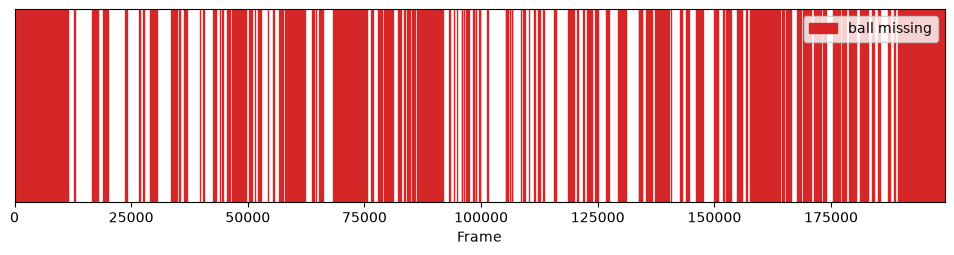

In [ ]:
print(f"teams: H = {tracking.home_name} | A = {tracking.away_name}")
print(f"frames: {tracking.n_frames} | slots: {tracking.players_xy.shape[1]}")
print(f"missing ATD records: {int((~tracking.record_seen).sum())}")
ball_seen = int((~np.isnan(tracking.ball_xy[:, 0])).sum())
print(f"ball seen on {ball_seen} frames ({100.0 * ball_seen / tracking.n_frames:.1f}%)")

ball_missing = np.isnan(tracking.ball_xy[:, 0])
edges = np.diff(np.r_[0, ball_missing.astype(int), 0])
starts = np.where(edges == 1)[0]
ends = np.where(edges == -1)[0]

fig, ax = plt.subplots(figsize=(12, 2.5))
ax.broken_barh(list(zip(starts, ends - starts)), (0, 1), color='tab:red', label='ball missing')
ax.set_xlim(0, tracking.n_frames)
ax.set_ylim(0, 1)
ax.set_yticks([])
ax.set_xlabel('Frame')
ax.legend(loc='upper right')
plt.show()

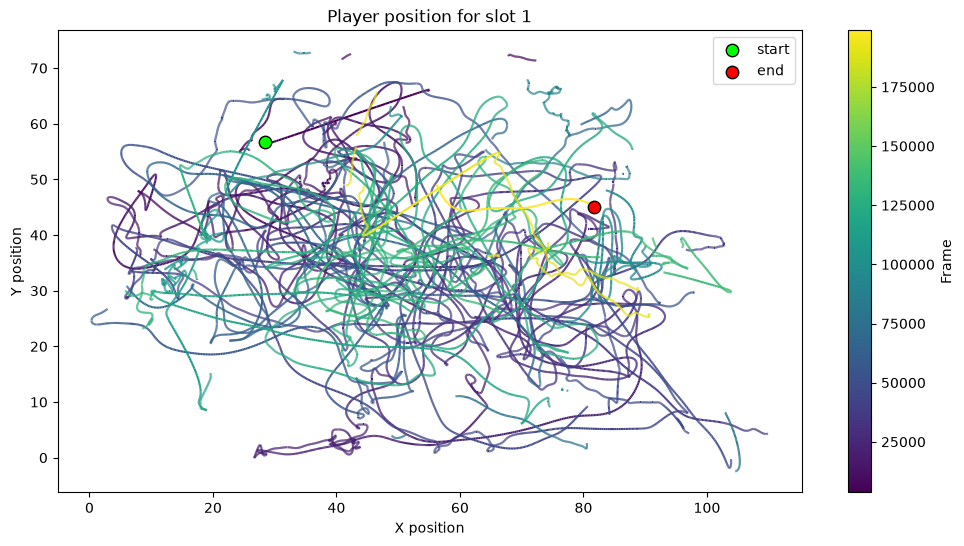

In [4]:
slot = 1
player_xy = tracking.players_xy[:, slot, :]
points = player_xy.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)
valid = ~np.isnan(segments).any(axis=(1, 2))
segments = segments[valid]
frame_idx = np.arange(len(player_xy) - 1)[valid]
fig, ax = plt.subplots(figsize=(12, 6))
lc = LineCollection(segments, cmap='viridis', linewidth=1.5)
lc.set_array(frame_idx)
ax.add_collection(lc)
ax.autoscale()
ax.set_xlabel('X position')
ax.set_ylabel('Y position')
ax.set_title(f'Player position for slot {slot}')
fig.colorbar(lc, ax=ax, label='Frame')
first = np.where(~np.isnan(player_xy[:, 0]))[0][[0, -1]]
ax.scatter(*player_xy[first[0]], color='lime', edgecolor='black', s=80, zorder=3, label='start')
ax.scatter(*player_xy[first[1]], color='red', edgecolor='black', s=80, zorder=3, label='end')
ax.legend()
plt.show()

  638 smart-tagging intervals


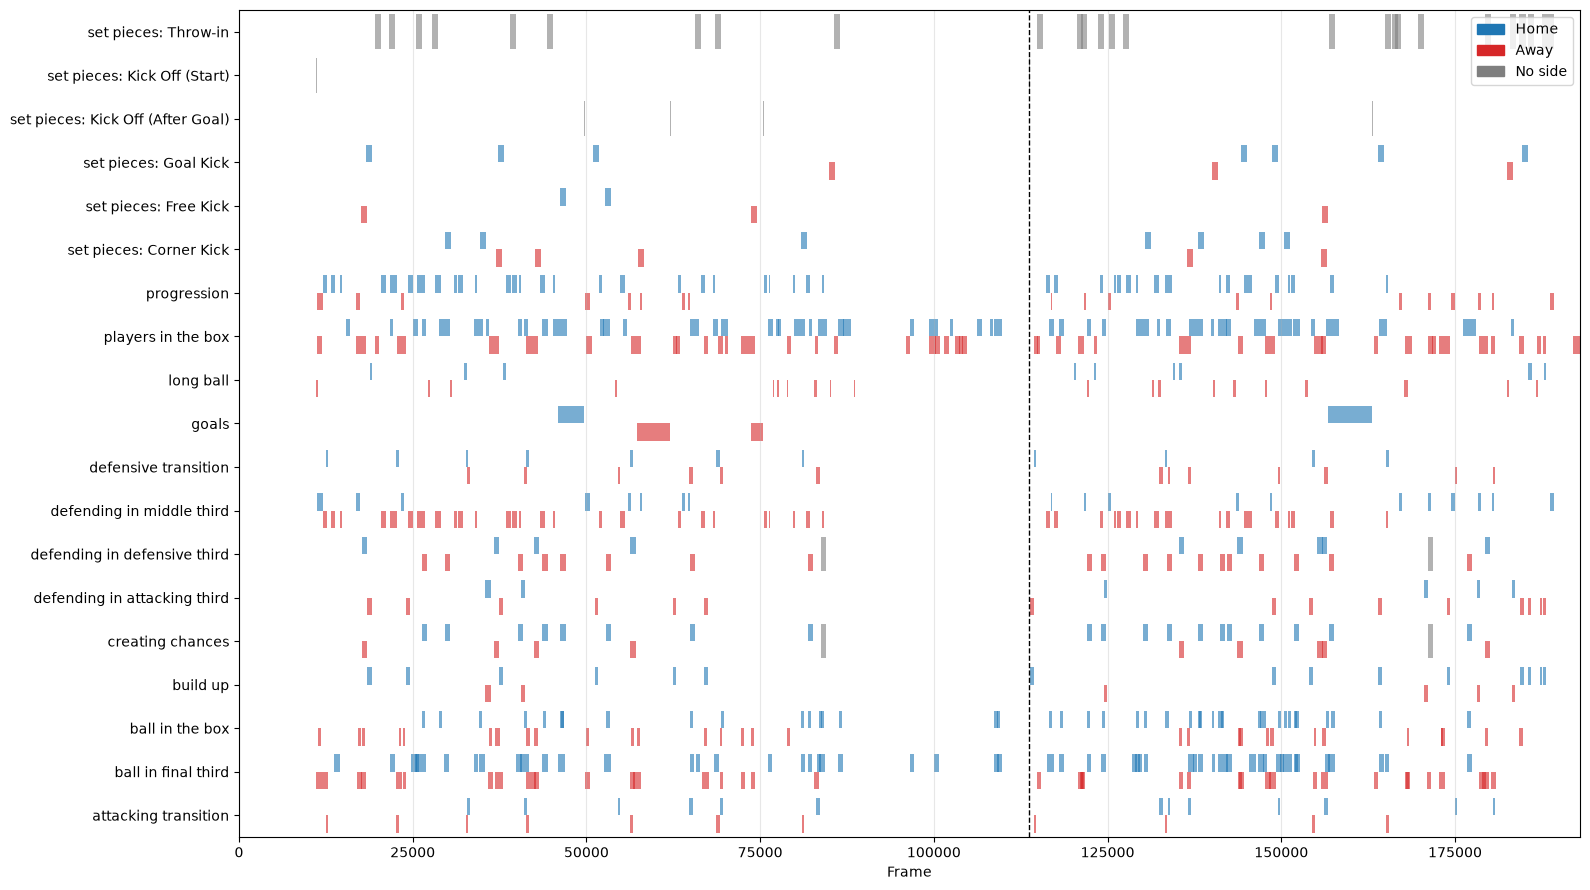

In [18]:
intervals = load_tag_intervals(tracking.home_name, tracking.away_name, GAME)
print(f"  {len(intervals)} smart-tagging intervals")

def row_label(t):
    if t.code == 'set pieces' and t.type:
        return f'set pieces: {t.type}'
    return t.code

labels = sorted({row_label(t) for t in intervals})
row_of = {lab: i for i, lab in enumerate(labels)}
colors = {'H': 'tab:blue', 'A': 'tab:red', None: 'tab:gray'}
lanes = {'H': (0.5, 0.4), 'A': (0.1, 0.4), None: (0.1, 0.8)}
fig, ax = plt.subplots(figsize=(16, 9))
for t in intervals:
    y0, h = lanes[t.side]
    row = row_of[row_label(t)]
    ax.broken_barh([(t.start_frame, t.end_frame - t.start_frame)],
                   (row + y0, h),
                   facecolors=colors[t.side], alpha=0.6, linewidth=0)

# mark the start of the 2nd half
second_half_start = min(t.start_frame for t in intervals if t.half == '2nd Half')
ax.axvline(second_half_start, color='black', linestyle='--', linewidth=1)

ax.set_yticks([i + 0.5 for i in range(len(labels))])
ax.set_yticklabels(labels)
ax.set_xlabel('Frame')
ax.set_xlim(0, max(t.end_frame for t in intervals))
ax.set_ylim(0, len(labels))
ax.grid(axis='x', alpha=0.3)
ax.legend(handles=[Patch(color='tab:blue', label='Home'),
                   Patch(color='tab:red', label='Away'),
                   Patch(color='tab:gray', label='No side')],
          loc='upper right')
plt.tight_layout()
plt.show()

In [30]:
def frame_to_time(frame):
    FRAME_RATE = 25
    seconds = frame / FRAME_RATE
    minutes = int(seconds // 60)
    seconds = int(seconds % 60)
    return f"{minutes:02d}:{seconds:02d}"

barca_goal_frame = min([i.start_frame for i in intervals if i.code == 'goals'])
print("first goal (barça)")
print("frame: ", barca_goal_frame)
print("time: ", frame_to_time(barca_goal_frame))

first goal (barça)
frame:  45947
time:  30:37


# Quality

In [35]:
from src.quality import compute_quality
from src.config import CONFIG
fps = GAMES[GAME]["fps"]

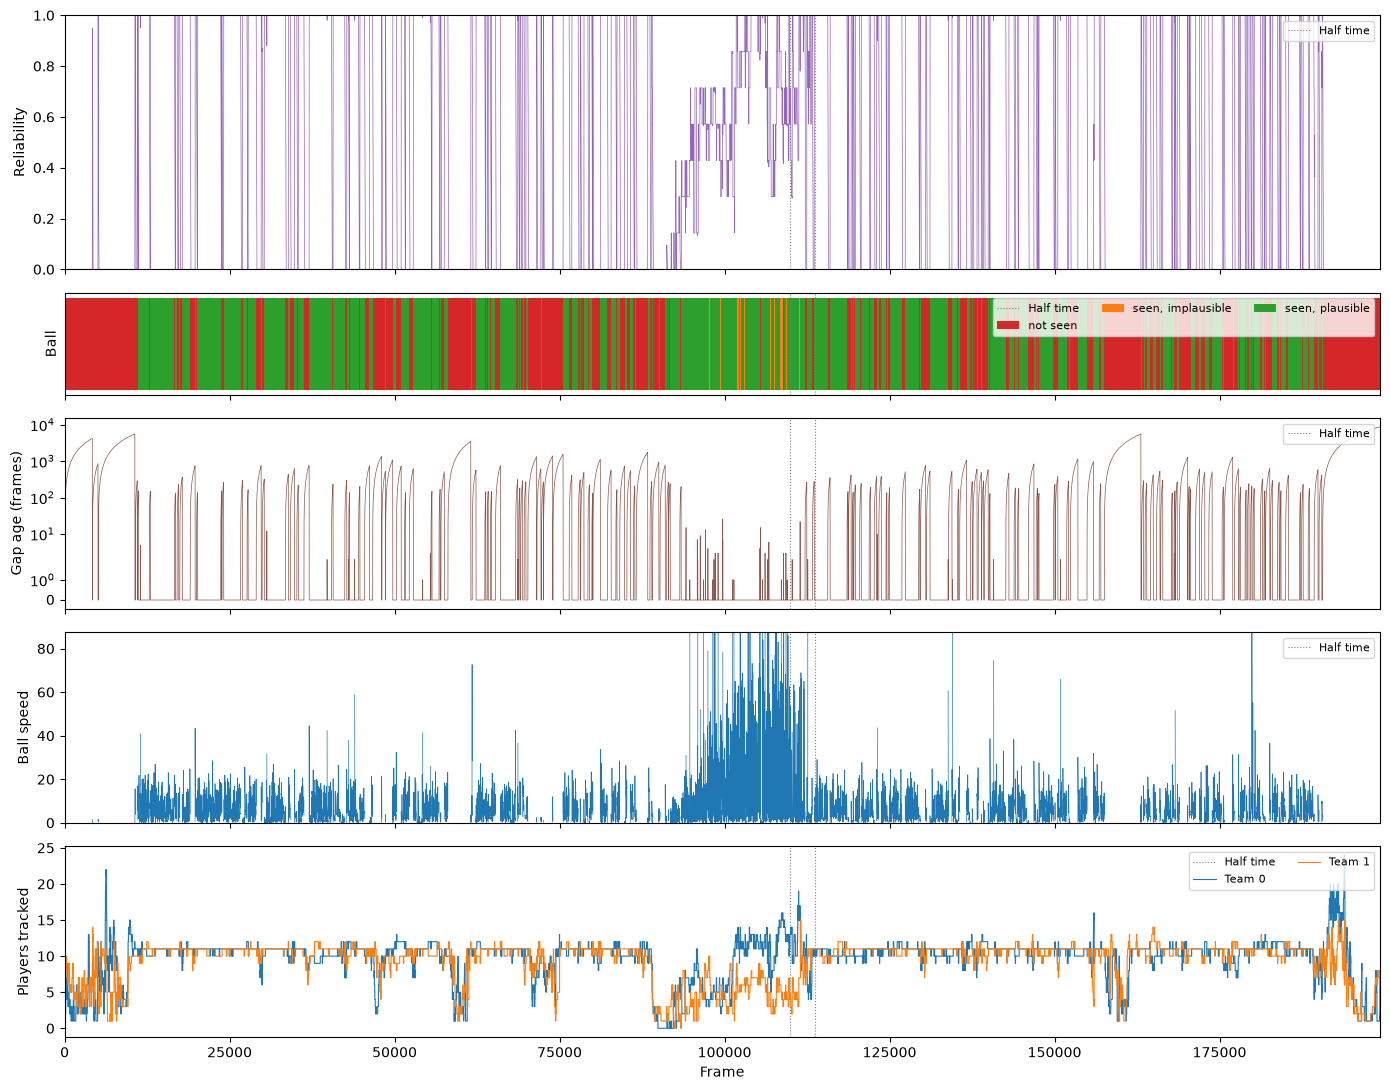

In [64]:
quality = compute_quality(tracking, CONFIG.quality, fps)
n = len(quality.ball_seen)
frames = np.arange(n)

def runs(mask):
    """(start, length) pairs for each contiguous run of True."""
    edges = np.diff(np.r_[0, mask.astype(int), 0])
    s, e = np.where(edges == 1)[0], np.where(edges == -1)[0]
    return list(zip(s, e - s))

fig, axes = plt.subplots(5, 1, figsize=(14, 11), sharex=True,
                         gridspec_kw={'height_ratios': [2, 0.8, 1.5, 1.5, 1.5]})

# half time line
first_half_end = max(t.end_frame for t in intervals if t.half == '1st Half')
second_half_start = min(t.start_frame for t in intervals if t.half == '2nd Half')
for ax in axes:
    ax.axvline(first_half_end, color='gray', linestyle=':', lw=0.8)
    ax.axvline(second_half_start, color='gray', linestyle=':', lw=0.8)
    ax.plot([], [], color='gray', linestyle=':', lw=0.8, label='Half time')
    ax.legend(loc='upper right', ncol=3, fontsize=8)

# 1. overall reliability
axes[0].plot(frames, quality.reliability, lw=0.5, color='tab:purple')
axes[0].set_ylabel('Reliability')
axes[0].set_ylim(0, 1)

# 2. ball status strip: seen / seen but implausible / not seen
ax = axes[1]
ax.broken_barh(runs(~quality.ball_seen), (0, 1), facecolors='tab:red', label='not seen')
ax.broken_barh(runs(quality.ball_seen & ~quality.ball_plausible), (0, 1), facecolors='tab:orange', label='seen, implausible')
ax.broken_barh(runs(quality.ball_seen & quality.ball_plausible), (0, 1), facecolors='tab:green', label='seen, plausible')
ax.set_yticks([])
ax.set_ylabel('Ball')
ax.legend(loc='upper right', ncol=3, fontsize=8)

# 3. frames since the ball was last seen
axes[2].plot(frames, quality.gap_age, lw=0.5, color='tab:brown')
axes[2].set_yscale('symlog')
axes[2].set_ylabel('Gap age (frames)')

# 4. ball speed (NaN where unavailable, so it breaks the line)
axes[3].plot(frames, quality.ball_speed, lw=0.5, color='tab:blue')
axes[3].set_ylim(0, np.nanpercentile(quality.ball_speed, 99.9))  # clip outlier spikes
axes[3].set_ylabel('Ball speed')

# 5. number of players tracked per team
axes[4].step(frames, quality.team_coverage[:, 0], where='post', lw=0.8, label='Team 0')
axes[4].step(frames, quality.team_coverage[:, 1], where='post', lw=0.8, label='Team 1')
axes[4].set_ylabel('Players tracked')
axes[4].legend(loc='upper right', ncol=2, fontsize=8)

axes[-1].set_xlabel('Frame')
axes[-1].set_xlim(0, n)
plt.tight_layout()
plt.show()

# Features + Evidence

# Decoder (temporal)